**1: Ingestion & Signal Construction**

In [18]:
# =========================================================================
# Cell 1: Environment Setup, Data Ingestion & Asymmetric Regime Signal
# =========================================================================
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Matplotlib styling for professional dark/light readability
plt.style.use(
    "seaborn-v0_8-whitegrid"
    if "seaborn-v0_8-whitegrid" in plt.style.available
    else "default"
)

# 1. Load the cleaned dataset exported from Notebook 01
DATA_PATH = "kplc_clean_nse_data.csv"
df = pd.read_csv(DATA_PATH)
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date").reset_index(drop=True)

# 2. Construct Core Features
# Trend baseline: 50-day Simple Moving Average
df["SMA_50"] = df["Price"].rolling(window=50).mean()

# Flow momentum: 10-day rolling cumulative net foreign flow (KES)
df["Roll_Flow_10D"] = df["Net_Foreign_Flow"].rolling(window=10).sum()

# Daily traded turnover in KES
df["Turnover_KES"] = df["Price"] * df["Volume"]

# 3. Asymmetric State-Machine with Deadband Hysteresis
# Rule Logic:
# - Entry (1.0): Price > SMA_50 (Uptrend) AND 10D Flow > 0 (Offshore Accumulation)
# - Exit  (0.0): Price < SMA_50 (Trend broken) OR 10D Flow < -2,000,000 (Aggressive Outflow)
# - Deadband:    Between these boundaries, retain prior state (prevents fee churn)
raw_positions = []
current_state = 0.0

for p, sma, flow in zip(df["Price"], df["SMA_50"], df["Roll_Flow_10D"]):
    if pd.isna(sma) or pd.isna(flow):
        raw_positions.append(0.0)
        continue

    if p > sma and flow > 0:
        current_state = 1.0  # Enter or maintain Long
    elif p < sma or flow < -2e6:
        current_state = 0.0  # Exit or maintain Cash
    # Otherwise, current_state remains unchanged (hysteresis)

    raw_positions.append(current_state)

df["Raw_Position"] = raw_positions

# 4. Strict Lookahead-Bias Prevention: Shift execution to t+1
# Signal finalized at Day t Close executes on Day t+1
df["Position"] = df["Raw_Position"].shift(1).fillna(0.0)

# 5. Diagnostic Summary
trade_flips = int(df["Position"].diff().abs().sum())
long_sessions = int((df["Position"] == 1.0).sum())
cash_sessions = int((df["Position"] == 0.0).sum())
total_sessions = len(df)

print("=== Cell 1 Execution Summary ===")
print(f"Dataset Range:         {df['Date'].min().strftime('%Y-%m-%d')} to {df['Date'].max().strftime('%Y-%m-%d')}")
print(f"Total Trading Days:    {total_sessions}")
print(f"Long Allocations:      {long_sessions} sessions ({long_sessions / total_sessions * 100:.1f}%)")
print(f"Cash Allocations:      {cash_sessions} sessions ({cash_sessions / total_sessions * 100:.1f}%)")
print(f"Total Trade Flips:     {trade_flips} across ~9 years")

=== Cell 1 Execution Summary ===
Dataset Range:         2017-06-09 to 2026-06-29
Total Trading Days:    2319
Long Allocations:      542 sessions (23.4%)
Cash Allocations:      1777 sessions (76.6%)
Total Trade Flips:     97 across ~9 years


**2: Vectorized Backtest with NSE Transaction Costs**

In [14]:
# -------------------------------------------------------------------------
# Cell 2 (Revised): Re-run Vectorized Backtest with 1.0% One-Way NSE Fee
# -------------------------------------------------------------------------
TRANSACTION_COST = 0.010  # 1.0% one-way NSE fee

df["Strat_Gross_Return"] = df["Position"] * df["Daily_Return"]
df["Trade_Occurred"] = df["Position"].diff().abs().fillna(0.0)
df["Strat_Net_Return"] = (
    df["Strat_Gross_Return"] - df["Trade_Occurred"] * TRANSACTION_COST
)

df["Equity_Benchmark"] = (1.0 + df["Daily_Return"]).cumprod()
df["Equity_Strategy_Gross"] = (1.0 + df["Strat_Gross_Return"]).cumprod()
df["Equity_Strategy_Net"] = (1.0 + df["Strat_Net_Return"]).cumprod()

# Recompute and display the scorecard
strat_metrics_revised = compute_performance_metrics(
    df["Strat_Net_Return"], df["Equity_Strategy_Net"]
)
scorecard_revised = pd.DataFrame(
    {
        "Buy & Hold (KPLC)": bench_metrics,
        "Filtered Flow Strategy (Net)": strat_metrics_revised,
    }
)

print("=== Revised Performance Scorecard (With Hysteresis) ===")
print(scorecard_revised.to_string())

=== Revised Performance Scorecard (With Hysteresis) ===
                     Buy & Hold (KPLC) Filtered Flow Strategy (Net)
Total Return                   112.27%                       19.41%
CAGR                             8.52%                        1.95%
Annual Volatility               42.42%                       27.01%
Sharpe Ratio (Rf=9%)             -0.01                        -0.26
Sortino Ratio                    -0.02                        -0.24
Max Drawdown                   -89.36%                      -74.87%
Calmar Ratio                      0.10                         0.03


**3: Performance Scorecard Function**

In [15]:
# -------------------------------------------------------------------------
# Cell 3: Professional Quant Performance Metrics
# -------------------------------------------------------------------------
def compute_performance_metrics(
    return_series: pd.Series, equity_series: pd.Series, risk_free_rate=0.09
) -> dict:
    """Calculates CAGR, Annualized Volatility, Sharpe, Sortino, and Max Drawdown.

    risk_free_rate defaults to 9% (approximating historical CBK 91-day T-Bill).
    """
    total_days = len(return_series)
    trading_days_per_year = 252

    # Total Return and CAGR
    total_return = equity_series.iloc[-1] - 1.0
    years = total_days / trading_days_per_year
    cagr = (equity_series.iloc[-1]) ** (1.0 / years) - 1.0

    # Annualized Volatility
    ann_vol = return_series.std() * np.sqrt(trading_days_per_year)

    # Sharpe Ratio
    excess_return = cagr - risk_free_rate
    sharpe = excess_return / ann_vol if ann_vol > 0 else 0.0

    # Downside Volatility & Sortino Ratio
    downside_returns = return_series[return_series < 0]
    downside_vol = downside_returns.std() * np.sqrt(trading_days_per_year)
    sortino = excess_return / downside_vol if downside_vol > 0 else 0.0

    # Maximum Drawdown
    rolling_max = equity_series.cummax()
    drawdowns = (equity_series - rolling_max) / rolling_max
    max_drawdown = drawdowns.min()

    # Calmar Ratio
    calmar = cagr / abs(max_drawdown) if max_drawdown != 0 else 0.0

    return {
        "Total Return": f"{total_return * 100:.2f}%",
        "CAGR": f"{cagr * 100:.2f}%",
        "Annual Volatility": f"{ann_vol * 100:.2f}%",
        "Sharpe Ratio (Rf=9%)": f"{sharpe:.2f}",
        "Sortino Ratio": f"{sortino:.2f}",
        "Max Drawdown": f"{max_drawdown * 100:.2f}%",
        "Calmar Ratio": f"{calmar:.2f}",
    }


# Evaluate Benchmark vs. Strategy (Net)
bench_metrics = compute_performance_metrics(
    df["Bench_Return"], df["Equity_Benchmark"]
)
strat_metrics = compute_performance_metrics(
    df["Strat_Net_Return"], df["Equity_Strategy_Net"]
)

scorecard = pd.DataFrame(
    {"Buy & Hold (KPLC)": bench_metrics, "Foreign Flow Strategy (Net)": strat_metrics}
)

print("=== Institutional Performance Scorecard (2017 - 2026) ===")
print(scorecard.to_string())

=== Institutional Performance Scorecard (2017 - 2026) ===
                     Buy & Hold (KPLC) Foreign Flow Strategy (Net)
Total Return                   112.27%                      19.41%
CAGR                             8.52%                       1.95%
Annual Volatility               42.42%                      27.01%
Sharpe Ratio (Rf=9%)             -0.01                       -0.26
Sortino Ratio                    -0.02                       -0.24
Max Drawdown                   -89.36%                     -74.87%
Calmar Ratio                      0.10                        0.03


**4: Equity Curve & Drawdown Plot**

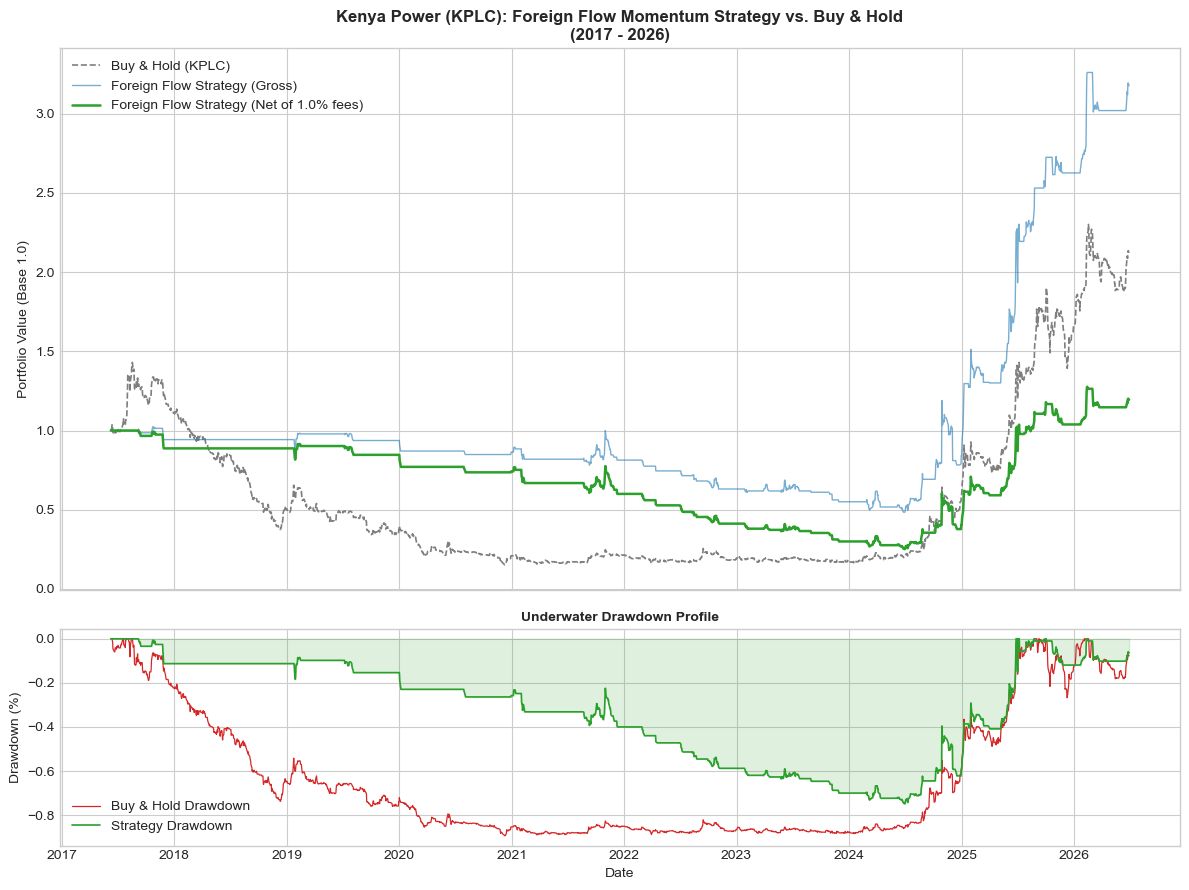

In [16]:
# -------------------------------------------------------------------------
# Cell 4: Visual Comparison (Equity Curves & Underwater Plot)
# -------------------------------------------------------------------------
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(12, 9), sharex=True, gridspec_kw={"height_ratios": [2.5, 1]}
)

# 1. Equity Curves
ax1.plot(
    df["Date"],
    df["Equity_Benchmark"],
    label="Buy & Hold (KPLC)",
    color="#7f7f7f",
    linewidth=1.2,
    linestyle="--",
)
ax1.plot(
    df["Date"],
    df["Equity_Strategy_Gross"],
    label="Foreign Flow Strategy (Gross)",
    color="#1f77b4",
    linewidth=1.0,
    alpha=0.6,
)
ax1.plot(
    df["Date"],
    df["Equity_Strategy_Net"],
    label="Foreign Flow Strategy (Net of 1.0% fees)",
    color="#2ca02c",
    linewidth=1.8,
)
ax1.set_title(
    "Kenya Power (KPLC): Foreign Flow Momentum Strategy vs. Buy & Hold\n(2017 - 2026)",
    fontsize=12,
    fontweight="bold",
)
ax1.set_ylabel("Portfolio Value (Base 1.0)")
ax1.legend(loc="upper left")

# 2. Underwater / Drawdown Chart
rolling_max_bench = df["Equity_Benchmark"].cummax()
dd_bench = (df["Equity_Benchmark"] - rolling_max_bench) / rolling_max_bench

rolling_max_strat = df["Equity_Strategy_Net"].cummax()
dd_strat = (df["Equity_Strategy_Net"] - rolling_max_strat) / rolling_max_strat

ax2.plot(
    df["Date"],
    dd_bench,
    color="#d62728",
    linewidth=0.9,
    label="Buy & Hold Drawdown",
)
ax2.plot(
    df["Date"],
    dd_strat,
    color="#2ca02c",
    linewidth=1.2,
    label="Strategy Drawdown",
)
ax2.fill_between(df["Date"], dd_strat, 0, color="#2ca02c", alpha=0.15)
ax2.set_title("Underwater Drawdown Profile", fontsize=10, fontweight="bold")
ax2.set_ylabel("Drawdown (%)")
ax2.set_xlabel("Date")
ax2.legend(loc="lower left")

plt.tight_layout()
plt.show()

In [17]:
# -------------------------------------------------------------------------
# Cell: Final Performance Comparison Table
# -------------------------------------------------------------------------
final_bench_metrics = compute_performance_metrics(
    df["Daily_Return"], df["Equity_Benchmark"]
)
final_strat_gross = compute_performance_metrics(
    df["Strat_Gross_Return"], df["Equity_Strategy_Gross"]
)
final_strat_net = compute_performance_metrics(
    df["Strat_Net_Return"], df["Equity_Strategy_Net"]
)

final_scorecard = pd.DataFrame(
    {
        "Buy & Hold (KPLC)": final_bench_metrics,
        "Flow Strategy (Gross)": final_strat_gross,
        "Flow Strategy (Net of 1.0% Fee)": final_strat_net,
    }
)

print("=" * 65)
print(" KENYA POWER (KPLC) QUANTITATIVE STRATEGY SCORECARD (2017-2026)")
print("=" * 65)
print(final_scorecard.to_string())
print("=" * 65)

 KENYA POWER (KPLC) QUANTITATIVE STRATEGY SCORECARD (2017-2026)
                     Buy & Hold (KPLC) Flow Strategy (Gross) Flow Strategy (Net of 1.0% Fee)
Total Return                   112.27%               217.49%                          19.41%
CAGR                             8.52%                13.38%                           1.95%
Annual Volatility               42.42%                26.69%                          27.01%
Sharpe Ratio (Rf=9%)             -0.01                  0.16                           -0.26
Sortino Ratio                    -0.02                  0.14                           -0.24
Max Drawdown                   -89.36%               -52.61%                         -74.87%
Calmar Ratio                      0.10                  0.25                            0.03
